# TTS nhẹ — benchmark cô lập (Arduino UNO Q 4GB)

- Mỗi giọng chạy trong tiến trình con riêng, ghi wav ra `tts_out/`, đo RAM theo delta.
- Độ dễ nghe (proxy): một STT **cố định** (faster-whisper base.en int8) nghe lại wav → round-trip WER.
  Judge chạy ở tiến trình khác nên **không** cộng vào RAM của TTS.
- Bỏ SpeechT5 (RAM lớn, RTF 0.4) và MMS-TTS (WER 0.21 ở lần chạy trước).
- Không phải MOS: không đo độ tự nhiên.

In [1]:
%pip install -q piper-tts faster-whisper jiwer soundfile librosa psutil pandas matplotlib huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys; sys.path.insert(0, ".")
from bench_common import *

TTS = [
    ("piper amy-low",    "tts_piper",  {"voice": "en_US-amy-low"}),
    ("piper amy-medium", "tts_piper",  {"voice": "en_US-amy-medium"}),
    ("piper lessac-low", "tts_piper",  {"voice": "en_US-lessac-low"}),
    ("espeak-ng",        "tts_espeak", {}),   # cần cài espeak-ng; bỏ qua nếu thiếu
]
for name, kind, params in TTS:
    out_dir = f"tts_out/{name.replace(' ', '_')}"
    row = bench("tts", name, kind, {**params, "out_dir": out_dir, "sentences": TEST_SENTENCES})
    if "error" not in row and "roundtrip_wer" not in row:
        j = run_isolated("wer_wavs", {"wav_dir": row["wav_dir"], "sentences": TEST_SENTENCES})
        if "error" in j:
            print("[judge ERROR]", name, j["error"][-300:])
        else:
            update_row("tts", name, **j)

[done] piper amy-low: ram_peak_mb=161.7, ram_total_peak_mb=234.2, rtf=0.024
[done] piper amy-medium: ram_peak_mb=191.9, ram_total_peak_mb=264.1, rtf=0.034
[done] piper lessac-low: ram_peak_mb=138.9, ram_total_peak_mb=211.0, rtf=0.025
[ERROR] espeak-ng:
Chưa cài espeak-ng (https://github.com/espeak-ng/espeak-ng/releases) hoặc đặt biến ESPEAK_CMD.



In [3]:
df = table("tts")
cols = ["model", "ram_total_peak_mb", "ram_runtime_mb", "ram_model_load_mb", "ram_peak_mb", "rtf",
        "roundtrip_wer", "onnx_mb", "runtime", "ram_note"]
df[[c for c in cols if c in df.columns]]

,model,ram_total_peak_mb,ram_runtime_mb,ram_model_load_mb,ram_peak_mb,rtf,roundtrip_wer,onnx_mb,runtime
0,piper amy-low,234.2,72.5,83.6,161.7,0.024,0.0421,60.2,onnxruntime(piper)
1,piper amy-medium,264.1,72.1,84.2,191.9,0.034,0.0421,60.3,onnxruntime(piper)
2,piper lessac-low,211.0,72.1,83.8,138.9,0.025,0.0526,60.3,onnxruntime(piper)


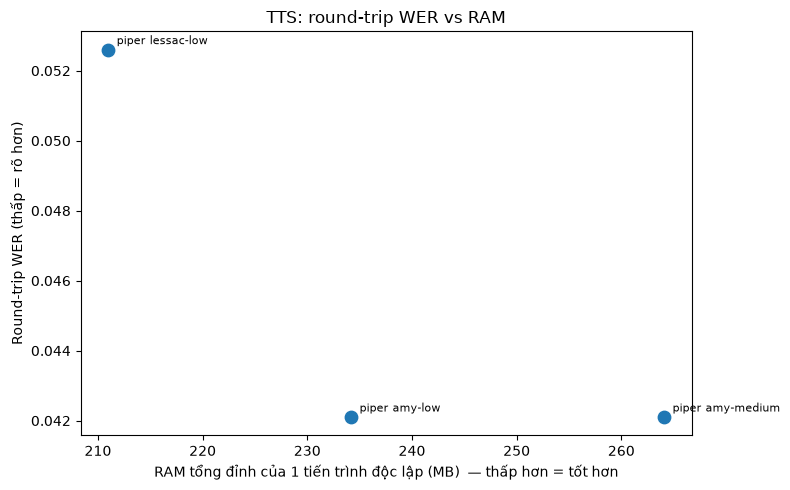

In [4]:
plot_tradeoff(df, "ram_total_peak_mb", "roundtrip_wer", "TTS: round-trip WER vs RAM", "Round-trip WER (thấp = rõ hơn)", "tts_lite.png")

## Lưu ý
- Nên **nghe thử** các file trong `tts_out/` — WER không nói được giọng có tự nhiên hay không.
- `espeak-ng` là tiến trình ngoài, RAM ghi là ước lượng (<20MB); hãy đo bằng Task Manager/`ps`.
- RTF trên PC không đại diện UNO Q; đo lại trên thiết bị. RTF > 1 là loại.